# Table of Contents

- [Packages](#0)
- [Utils](#1)
- [1 - Translating Human Readable Dates Into Machine Readable Dates](#2)
    - [1.1 - Dataset](#2-1)
- [2 - Neural Machine Translation with Attention](#3)
    - [2.1 - Attention Mechanism](#3-1)
        - [One-Step Attention](#3-1-1)
        - [Model](#3-1-2)
        - [Compiling the Model](#3-1-3)
- [3 - Visualizing Attention](#4)
    - [3.1 - Getting the Attention Weights From the Network](#4-1)

<a name='0'></a>
## Packages

In [1]:
import random

import numpy                    as np
import matplotlib.pyplot       as plt
import tensorflow.keras.backend as K

from babel.dates                 import format_date
from faker                       import Faker
from tensorflow.keras.models     import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils      import to_categorical
from tensorflow.keras.layers     import Bidirectional, Concatenate, Dot, Input, LSTM, RepeatVector, Dense, Activation
from tqdm                        import tqdm

<a name='1'></a>
## Utils

In [34]:
fake = Faker()

Faker.seed(99999)
random.seed(99999)


FORMATS = [
    'short',
    'medium',
    'long',
    'full',
    'full',
    'full',
    'full',
    'full',
    'full',
    'full',
    'full',
    'full',
    'full',
    'd MMM YYY',
    'd MMMM YYY',
    'dd MMM YYY',
    'd MMM, YYY',
    'd MMMM, YYY',
    'dd, MMM YYY',
    'd MM YY',
    'd MMMM YYY',
    'MMMM d YYY',
    'MMMM d, YYY',
    'dd.MM.YY'
]

LOCALES = ['en_US']


def load_date():
    """
        Loads some fake dates
        :returns: tuple containing human-readable string, machine-readable string, and date object
    """

    dt = fake.date_object()

    try:
        human_readable   = format_date(dt, format=random.choice(FORMATS), locale=random.choice(LOCALES))
        human_readable   = human_readable.lower()
        human_readable   = human_readable.replace(',','')
        machine_readable = dt.isoformat()

    except AttributeError:
        return None, None, None

    return human_readable, machine_readable, dt


def load_dataset(m):
    """
        Loads a dataset with m examples and vocabularies
        :m: the number of examples to generate
    """

    human_vocab   = set()
    machine_vocab = set()
    dataset       = []


    for _ in tqdm(range(m)):
        h, m, _ = load_date()
        if h is not None:
            dataset.append((h, m))
            human_vocab.update(tuple(h))
            machine_vocab.update(tuple(m))

    human       = dict(zip(sorted(human_vocab) + ['<unk>', '<pad>'], list(range(len(human_vocab) + 2))))
    inv_machine = dict(enumerate(sorted(machine_vocab)))
    machine     = {v:k for k,v in inv_machine.items()}

    return dataset, human, machine, inv_machine


def string_to_int(string, length, vocab):
    """
    Converts all strings in the vocabulary into a list of integers representing the positions of the
    input string's characters in the "vocab"

    Arguments:
    string -- input string, e.g. 'Tuesday 10 Jul 2007'
    length -- the number of time steps you'd like, determines if the output will be padded or cut
    vocab -- vocabulary, dictionary used to index every character of your "string"

    Returns:
    rep -- list of integers (or '<unk>') (size = length) representing the position of the string's character in the vocabulary
    """

    string = string.lower()
    string = string.replace(',','')

    if len(string) > length:
        string = string[:length]

    rep = list(map(lambda x: vocab.get(x, '<unk>'), string))

    if len(string) < length:
        rep += [vocab['<pad>']] * (length - len(string))

    return rep


def preprocess_data(dataset, human_vocab, machine_vocab, Tx, Ty):

    X, Y = zip(*dataset)

    X    = np.array([string_to_int(i, Tx, human_vocab) for i in X])
    Y    = [string_to_int(t, Ty, machine_vocab) for t in Y]

    Xoh  = np.array(list(map(lambda x: to_categorical(x, num_classes=len(human_vocab)),   X)))
    Yoh  = np.array(list(map(lambda x: to_categorical(x, num_classes=len(machine_vocab)), Y)))

    return X, np.array(Y), Xoh, Yoh


def softmax(x, axis=1):
    """Softmax activation function.
    # Arguments
        x : Tensor.
        axis: Integer, axis along which the softmax normalization is applied.
    # Returns
        Tensor, output of softmax transformation.
    # Raises
        ValueError: In case `dim(x) == 1`.
    """

    ndim = K.ndim(x)

    if ndim == 2:
        return K.softmax(x)

    elif ndim > 2:
        e = K.exp(x - K.max(x, axis=axis, keepdims=True))
        s = K.sum(e, axis=axis, keepdims=True)
        return e / s

    else:
        raise ValueError('Cannot apply softmax to a tensor that is 1D')


def int_to_string(ints, inv_vocab):
    """
    Output a machine-readable list of characters based on a list of indexes in the machine's vocabulary

    Arguments:
    ints -- list of integers representing indexes in the machine's vocabulary
    inv_vocab -- dictionary mapping machine-readable indexes to machine-readable characters

    Returns:
    l -- list of characters corresponding to the indexes of ints thanks to the inv_vocab mapping
    """

    l = [inv_vocab[i] for i in ints]
    return l


def plot_attention_map(modelx, input_vocabulary, inv_output_vocabulary, text, n_s = 128):
    """
    Plot the attention map.
    """

    attention_map    = np.zeros((10, 30))
    layer            = modelx.get_layer('attention_weights')
    Ty, Tx           = attention_map.shape
    human_vocab_size = 37

    # Well, this is cumbersome but this version of tensorflow-keras has a bug that affects the
    # reuse of layers in a model with the functional API.
    # So, I have to recreate the model based on the functional
    # components and connect then one by one.
    # ideally it can be done simply like this:
    # layer = modelx.layers[num]
    # f = Model(modelx.inputs, [layer.get_output_at(t) for t in range(Ty)])

    X  = modelx.inputs[0]
    s0 = modelx.inputs[1]
    c0 = modelx.inputs[2]
    s  = s0
    c  = s0
    a = modelx.layers[2](X)
    outputs = []

    for t in range(Ty):
        s_prev   = s
        s_prev   = modelx.layers[3](s_prev)
        concat   = modelx.layers[4]([a, s_prev])
        e        = modelx.layers[5](concat)
        energies = modelx.layers[6](e)
        alphas   = modelx.layers[7](energies)
        context  = modelx.layers[8]([alphas, a])
        s, _, c  = modelx.layers[10](context, initial_state = [s, c])
        outputs.append(energies)

    f       = Model(inputs=[X, s0, c0], outputs = outputs)
    s0      = np.zeros((1, n_s))
    c0      = np.zeros((1, n_s))
    encoded = np.array(string_to_int(text, Tx, input_vocabulary)).reshape((1, 30))
    encoded = np.array(list(map(lambda x: to_categorical(x, num_classes=len(input_vocabulary)), encoded)))

    r       = f([encoded, s0, c0])

    for t in range(Ty):
        for t_prime in range(Tx):
            attention_map[t][t_prime] = r[t][0, t_prime]

    # Normalize attention map
    row_max        = attention_map.max(axis=1)
    attention_map  = attention_map / row_max[:, None]

    prediction     = modelx.predict([encoded, s0, c0])

    predicted_text = []

    for i in range(len(prediction)):
        predicted_text.append(int(np.argmax(prediction[i], axis=1)))

    predicted_text = list(predicted_text)
    predicted_text = int_to_string(predicted_text, inv_output_vocabulary)
    text_          = list(text)

    # get the lengths of the string
    input_length  = len(text)
    output_length = Ty

    # Plot the attention_map
    plt.clf()
    f = plt.figure(figsize=(8, 8.5))
    ax = f.add_subplot(1, 1, 1)

    # add image
    i = ax.imshow(attention_map, interpolation='nearest', cmap='Blues')

    # add colorbar
    cbaxes = f.add_axes((0.20, 0.00, 0.60, 0.03))
    cbar = f.colorbar(i, cax=cbaxes, orientation='horizontal')
    cbar.ax.set_xlabel('Alpha value (Probability output of the "softmax")', labelpad=2)

    # add labels
    ax.set_yticks(range(output_length))
    ax.set_yticklabels(predicted_text[:output_length])

    ax.set_xticks(range(input_length))
    ax.set_xticklabels(text_[:input_length], rotation=45)

    ax.set_xlabel('Input Sequence')
    ax.set_ylabel('Output Sequence')

    # add grid and legend
    ax.grid()

    # f.show()

    return attention_map

<a name='2'></a>
## 1 - Translating Human Readable Dates Into Machine Readable Dates

<a name='2-1'></a>
### 1.1 - Dataset
- `X`: a processed version of the human-readable dates in the training set.
    - Each character in X is replaced by an index (integer) mapped to the character using `human_vocab`.
    - Each date is padded to ensure a length of $T_x$ using a special character (< pad >).
    - `X.shape = (m, Tx)` where m is the number of training examples in a batch.
- `Y`: a processed version of the machine-readable dates in the training set.
    - Each character is replaced by the index (integer) it is mapped to in `machine_vocab`.
    - `Y.shape = (m, Ty)`.
- `Xoh`: one-hot version of `X`
    - Each index in `X` is converted to the one-hot representation (if the index is 2, the one-hot version has the index position 2 set to 1, and the remaining positions are 0).
    - `Xoh.shape = (m, Tx, len(human_vocab))`
- `Yoh`: one-hot version of `Y`
    - Each index in `Y` is converted to the one-hot representation.
    - `Yoh.shape = (m, Ty, len(machine_vocab))`.
    - `len(machine_vocab) = 11` since there are 10 numeric digits (0 to 9) and the `-` symbol.

In [3]:
m = 10000
dataset, human_vocab, machine_vocab, inv_machine_vocab = load_dataset(m)
dataset[:10]

100%|██████████| 10000/10000 [00:00<00:00, 42073.93it/s]


[('tuesday march 14 1978', '1978-03-14'),
 ('18 jan 1991', '1991-01-18'),
 ('monday january 12 2004', '2004-01-12'),
 ('monday march 24 2014', '2014-03-24'),
 ('sunday april 26 2020', '2020-04-26'),
 ('mar 11 1986', '1986-03-11'),
 ('4 mar 1994', '1994-03-04'),
 ('february 26 1998', '1998-02-26'),
 ('saturday october 15 1983', '1983-10-15'),
 ('april 5 1987', '1987-04-05')]

In [4]:
Tx = 30
Ty = 10
X, Y, Xoh, Yoh = preprocess_data(dataset, human_vocab, machine_vocab, Tx, Ty)

print("X.shape   : ", X.shape)
print("Y.shape   : ", Y.shape)
print("Xoh.shape : ", Xoh.shape)
print("Yoh.shape : ", Yoh.shape)

X.shape   :  (10000, 30)
Y.shape   :  (10000, 10)
Xoh.shape :  (10000, 30, 37)
Yoh.shape :  (10000, 10, 11)


In [5]:
index = 0
print("Source date :", dataset[index][0])
print("Target date :", dataset[index][1])
print()
print("Source after preprocessing (indices) :", X[index])
print("Target after preprocessing (indices) :", Y[index])
print()
print("Source after preprocessing (one-hot) :", Xoh[index])
print("Target after preprocessing (one-hot) :", Yoh[index])

Source date : tuesday march 14 1978
Target date : 1978-03-14

Source after preprocessing (indices) : [30 31 17 29 16 13 34  0 24 13 28 15 20  0  4  7  0  4 12 10 11 36 36 36
 36 36 36 36 36 36]
Target after preprocessing (indices) : [ 2 10  8  9  0  1  4  0  2  5]

Source after preprocessing (one-hot) : [[0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 1.]
 [0. 0. 0. ... 0. 0. 1.]
 [0. 0. 0. ... 0. 0. 1.]]
Target after preprocessing (one-hot) : [[0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0.]
 [1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]]


<a name='3'></a>
## 2 - Neural Machine Translation with Attention

<a name='3-1'></a>
### 2.1 - Attention Mechanism
* Here is a figure to remind you how the model works.
    * The diagram on the left shows the attention model.
    * The diagram on the right shows what one "attention" step does to calculate the attention variables $\alpha^{\langle t, t' \rangle}$.
    * The attention variables $\alpha^{\langle t, t' \rangle}$ are used to compute the context variable $context^{\langle t \rangle}$ for each timestep in the output ($t=1, \ldots, T_y$).

#### Pre-attention and Post-attention LSTMs on both sides of the attention mechanism
- There are two separate LSTMs in this model (see diagram on the left): pre-attention and post-attention LSTMs.
- *Pre-attention* Bi-LSTM is the one at the bottom of the picture is a Bi-directional LSTM and comes *before* the attention mechanism.
    - The attention mechanism is shown in the middle of the left-hand diagram.
    - The pre-attention Bi-LSTM goes through $T_x$ time steps
- *Post-attention* LSTM: at the top of the diagram comes *after* the attention mechanism.
    - The post-attention LSTM goes through $T_y$ time steps.

- The post-attention LSTM passes the hidden state $s^{\langle t \rangle}$ and cell state $c^{\langle t \rangle}$ from one time step to the next.


<table>
<td>
<img src="../images/attn_model.png" style="width:500;height:500px;"> <br>
</td>
<td>
<img src="../images/attn_mechanism.png" style="width:500;height:500px;"> <br>
</td>
</table>
<caption><center> **Figure 1**: Neural machine translation with attention</center></caption>

<a name='3-1-1'></a>
#### One-Step Attention

In [6]:
repeator     = RepeatVector(Tx)
concatenator = Concatenate(axis=-1)
densor1      = Dense(10, activation = "tanh")
densor2      = Dense(1, activation = "relu")
activator    = Activation(softmax, name='attention_weights')
dotor        = Dot(axes = 1)

In [7]:
def one_step_attention(a, s_prev):
    """
    Performs one step of attention: Outputs a context vector computed as a dot product of the attention weights
    "alphas" and the hidden states "a" of the Bi-LSTM.

    Arguments:
    a -- hidden state output of the Bi-LSTM, numpy-array of shape (m, Tx, 2*n_a)
    s_prev -- previous hidden state of the (post-attention) LSTM, numpy-array of shape (m, n_s)

    Returns:
    context -- context vector, input of the next (post-attention) LSTM cell
    """

    # Use repeator to repeat s_prev to be of shape (m, Tx, n_s) so that you can concatenate it with all hidden states "a".
    s_prev   = repeator(s_prev)
    # Use concatenator to concatenate a and s_prev on the last axis.
    # For grading purposes, please list 'a' first and 's_prev' second, in this order.
    concat   = concatenator([a, s_prev])
    # Use densor1 to propagate concat through a small fully-connected neural network to compute the "intermediate energies" variable e.
    e        = densor1(concat)
    # Use densor2 to propagate e through a small fully-connected neural network to compute the "energies" variable energies.
    energies = densor2(e)
    # Use "activator" on "energies" to compute the attention weights "alphas".
    alphas   = activator(energies)
    # Use dotor together with "alphas" and "a", in this order, to compute the context vector to be given to the next (post-attention) LSTM-cell
    context  = dotor([alphas, a])

    return context

<a name='3-1-2'></a>
#### Model

In [8]:
n_a = 32 # number of units for the pre-attention, bidirectional LSTM's hidden state 'a'
n_s = 64 # number of units for the post-attention LSTM's hidden state "s"

post_activation_LSTM_cell = LSTM(n_s, return_state = True)
output_layer              = Dense(len(machine_vocab), activation=softmax)

In [12]:
def model(Tx, Ty, n_a, n_s, human_vocab_size, machine_vocab_size=None):
    """
    Arguments:
    Tx -- length of the input sequence
    Ty -- length of the output sequence
    n_a -- hidden state size of the Bi-LSTM
    n_s -- hidden state size of the post-attention LSTM
    human_vocab_size -- size of the python dictionary "human_vocab"
    machine_vocab_size -- integer, optional, size of the python dictionary "machine_vocab"
                          This is not being used

    Returns:
    model -- Keras model instance
    """

    # Define the inputs of your model with a shape (Tx, human_vocab_size)
    # Define s0 (initial hidden state) and c0 (initial cell state)
    # for the decoder LSTM with shape (n_s,)
    X = Input(shape=(Tx, human_vocab_size))
    # initial hidden state
    s0 = Input(shape=(n_s,), name='s0')
    # initial cell state
    c0 = Input(shape=(n_s,), name='c0')
    # hidden state
    s = s0
    # cell state
    c = c0

    # Initialize empty list of outputs
    outputs = []

    # Step 1: Define your pre-attention Bi-LSTM.
    a = Bidirectional(LSTM(units=n_a, return_sequences=True))(X)

    # Step 2: Iterate for Ty steps.
    for t in range(Ty):

        # Step 2.A: Perform one step of the attention mechanism to get back the context vector at step t.
        context = one_step_attention(a, s)

        # Step 2.B: Apply the post-attention LSTM cell to the "context" vector.
        # Don't forget to pass: initial_state = [hidden state, cell state]
        # Remember: s = hidden state, c = cell state
        _, s, c = post_activation_LSTM_cell(context, initial_state = [s, c])

        # Step 2.C: Apply Dense layer to the hidden state output of the post-attention LSTM.
        out = output_layer(s)

        # Step 2.D: Append "out" to the "outputs" list.
        outputs.append(out)

    # Step 3: Create model instance taking three inputs and returning the list of outputs.
    model = Model(inputs=[X,s0,c0], outputs=outputs)

    return model

In [13]:
model = model(Tx, Ty, n_a, n_s, len(human_vocab))
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 30, 37)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ s0 (InputLayer)     │ (None, 64)        │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_2     │ (None, 30, 64)    │     17,920 │ input_layer_2[0]… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ repeat_vector       │ (None, 30, 64)    │          0 │ s0[0][0],         │
│ (RepeatVector)      │                   │            │ lstm[0][1],       │
│                     │                   │            │ lstm[1][1],       │
│                     │                   │            │ lstm[2][1],       │
│                     │                   │            │ lstm[3][1],       │
│                     │                   │            │ lstm[4][1],       │
│                     │                   │            │ lstm[5][1],       │
│                     │                   │            │ lstm[6][1],       │
│                     │                   │            │ lstm[7][1],       │
│                     │                   │            │ lstm[8][1]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 30, 128)   │          0 │ bidirectional_2[… │
│ (Concatenate)       │                   │            │ repeat_vector[2]… │
│                     │                   │            │ bidirectional_2[… │
│                     │                   │            │ repeat_vector[3]… │
│                     │                   │            │ bidirectional_2[… │
│                     │                   │            │ repeat_vector[4]… │
│                     │                   │            │ bidirectional_2[… │
│                     │                   │            │ repeat_vector[5]… │
│                     │                   │            │ bidirectional_2[… │
│                     │                   │            │ repeat_vector[6]… │
│                     │                   │            │ bidirectional_2[… │
│                     │                   │            │ repeat_vector[7]… │
│                     │                   │            │ bidirectional_2[… │
│                     │                   │            │ repeat_vector[8]… │
│                     │                   │            │ bidirectional_2[… │
│                     │                   │            │ repeat_vector[9]… │
│                     │                   │            │ bidirectional_2[… │
│                     │                   │            │ repeat_vector[10… │
│                     │                   │            │ bidirectional_2[… │
│                     │                   │            │ repeat_vector[11… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 30, 10)    │      1,290 │ concatenate[2][0… │
│                     │                   │            │ concatenate[3][0… │
│                     │                   │            │ concatenate[4][0… │
│                     │                   │            │ concatenate[5][0… │
│                     │                   │            │ concatenate[6][0… │
│                     │                   │            │ concatenate[7][0… │
│                     │                   │            │ concatenate[8][0… │
│                     │                   │            │ concatenate[9][0… │
│                     │                   │            │ concatenate[10][

 Total params: 52,960 (206.88 KB)

 Trainable params: 52,960 (206.88 KB)

 Non-trainable params: 0 (0.00 B)

<a name='3-1-3'></a>
#### Compiling the Model

In [23]:
opt = Adam(learning_rate=0.005, beta_1=0.9, beta_2=0.999, decay=0.01)
model.compile(loss = 'categorical_crossentropy', optimizer=opt, metrics=['accuracy']*10)

In [24]:
s0      = np.zeros((m, n_s))
c0      = np.zeros((m, n_s))
outputs = list(Yoh.swapaxes(0,1))

In [25]:
model.fit([Xoh, s0, c0], outputs, epochs=10, batch_size=64)

Epoch 1/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 11s 17ms/step - dense_2_accuracy: 0.7581 - dense_2_accuracy_1: 0.8133 - dense_2_accuracy_2: 0.3453 - dense_2_accuracy_3: 0.1131 - dense_2_accuracy_4: 0.9833 - dense_2_accuracy_5: 0.5622 - dense_2_accuracy_6: 0.1707 - dense_2_accuracy_7: 0.9336 - dense_2_accuracy_8: 0.3162 - dense_2_accuracy_9: 0.1214 - dense_2_loss: 2.4748 - loss: 13.5509
Epoch 2/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - dense_2_accuracy: 0.9729 - dense_2_accuracy_1: 0.9736 - dense_2_accuracy_2: 0.6044 - dense_2_accuracy_3: 0.3648 - dense_2_accuracy_4: 0.9999 - dense_2_accuracy_5: 0.9615 - dense_2_accuracy_6: 0.5337 - dense_2_accuracy_7: 0.9999 - dense_2_accuracy_8: 0.5561 - dense_2_accuracy_9: 0.2556 - dense_2_loss: 2.0455 - loss: 7.4040
Epoch 3/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - dense_2_accuracy: 0.9857 - dense_2_accuracy_1: 0.9863 - dense_2_accuracy_2: 0.8427 - dense_2_accuracy_3: 0.8271 - dense_2_accuracy_4: 1.0000 - dense_2_accuracy_5: 0.9701 - dense_2_accur

In [29]:
model.save_weights('../models/model.weights.h5')
model.save('../models/model.h5')
model.save('../model.keras')

In [30]:
model.load_weights('../models/model.h5')

In [31]:
EXAMPLES = [
    '3 May 1979',
    '5 April 09',
    '21th of August 2016',
    'Tue 10 Jul 2007',
    'Saturday May 9 2018',
    'March 3 2001',
    'March 3rd 2001',
    '1 March 2001'
]

s00 = np.zeros((1, n_s))
c00 = np.zeros((1, n_s))

for example in EXAMPLES:
    source     = string_to_int(example, Tx, human_vocab)
    source     = np.array(list(map(lambda x: to_categorical(x, num_classes=len(human_vocab)), source))).swapaxes(0,1)
    source     = np.swapaxes(source, 0, 1)
    source     = np.expand_dims(source, axis=0)
    prediction = model.predict([source, s00, c00])
    prediction = np.argmax(prediction, axis = -1)
    output     = [inv_machine_vocab[int(i)] for i in prediction]

    print("source:", example)
    print("output:", ''.join(output),"\n")

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 924ms/step
source: 3 May 1979
output: 1979-05-03 

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
source: 5 April 09
output: 2009-04-05 

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
source: 21th of August 2016
output: 2016-08-21 

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
source:

C:\Users\Legion\AppData\Local\Temp\ipykernel_44924\304443375.py:22: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  output     = [inv_machine_vocab[int(i)] for i in prediction]


 Tue 10 Jul 2007
output: 2007-07-10 

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
source: Saturday May 9 2018
output: 2018-05-09 

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step
source: March 3 2001
output: 2001-03-03 

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
source: March 3rd 2001
output: 2001-03-03 

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
source: 1 March 2001
output: 2001-03-01 



<a name='4'></a>
## 3 - Visualizing Attention

<a name='4-1'></a>
### 3.1 - Getting the Attention Weights From the Network

In [32]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 30, 37)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ s0 (InputLayer)     │ (None, 64)        │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_2     │ (None, 30, 64)    │     17,920 │ input_layer_2[0]… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ repeat_vector       │ (None, 30, 64)    │          0 │ s0[0][0],         │
│ (RepeatVector)      │                   │            │ lstm[0][1],       │
│                     │                   │            │ lstm[1][1],       │
│                     │                   │            │ lstm[2][1],       │
│                     │                   │            │ lstm[3][1],       │
│                     │                   │            │ lstm[4][1],       │
│                     │                   │            │ lstm[5][1],       │
│                     │                   │            │ lstm[6][1],       │
│                     │                   │            │ lstm[7][1],       │
│                     │                   │            │ lstm[8][1]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 30, 128)   │          0 │ bidirectional_2[… │
│ (Concatenate)       │                   │            │ repeat_vector[2]… │
│                     │                   │            │ bidirectional_2[… │
│                     │                   │            │ repeat_vector[3]… │
│                     │                   │            │ bidirectional_2[… │
│                     │                   │            │ repeat_vector[4]… │
│                     │                   │            │ bidirectional_2[… │
│                     │                   │            │ repeat_vector[5]… │
│                     │                   │            │ bidirectional_2[… │
│                     │                   │            │ repeat_vector[6]… │
│                     │                   │            │ bidirectional_2[… │
│                     │                   │            │ repeat_vector[7]… │
│                     │                   │            │ bidirectional_2[… │
│                     │                   │            │ repeat_vector[8]… │
│                     │                   │            │ bidirectional_2[… │
│                     │                   │            │ repeat_vector[9]… │
│                     │                   │            │ bidirectional_2[… │
│                     │                   │            │ repeat_vector[10… │
│                     │                   │            │ bidirectional_2[… │
│                     │                   │            │ repeat_vector[11… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 30, 10)    │      1,290 │ concatenate[2][0… │
│                     │                   │            │ concatenate[3][0… │
│                     │                   │            │ concatenate[4][0… │
│                     │                   │            │ concatenate[5][0… │
│                     │                   │            │ concatenate[6][0… │
│                     │                   │            │ concatenate[7][0… │
│                     │                   │            │ concatenate[8][0… │
│                     │                   │            │ concatenate[9][0… │
│                     │                   │            │ concatenate[10][

 Total params: 158,882 (620.64 KB)

 Trainable params: 52,960 (206.88 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 105,922 (413.76 KB)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step


C:\Users\Legion\AppData\Local\Temp\ipykernel_44924\286709536.py:215: RuntimeWarning: invalid value encountered in divide
  attention_map  = attention_map / row_max[:, None]
C:\Users\Legion\AppData\Local\Temp\ipykernel_44924\286709536.py:222: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  predicted_text.append(int(np.argmax(prediction[i], axis=1)))


<Figure size 640x480 with 0 Axes>

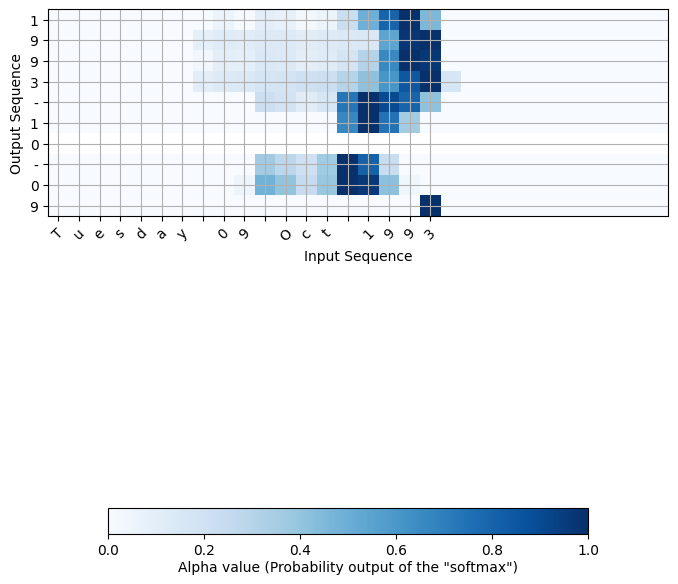

In [35]:
attention_map = plot_attention_map(model, human_vocab, inv_machine_vocab, "Tuesday 09 Oct 1993", num = 7, n_s = 64);